In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [29]:
from pathlib import Path
import sys

project_root = Path.cwd()
if not (project_root / "pkg_utilities").is_dir():
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from pkg_utilities.graph_plotting_functions import plot_single, plot_secondary, plot_numeric_feature
from pkg_utilities.utils import numeric_diagnostics

In [3]:
from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    average_precision_score
)

In [4]:
train = pd.read_csv("../data/train.csv")
test = pd.read_csv("../data/test.csv")

In [5]:
train.head()

,income,loan_amount,term_length,install_to_inc,schufa,OBS_DATE,target_var,occup_code_1,occup_code_2,occup_code_3,...,occup_nan,marital_Divorced,marital_Living together,marital_Married,marital_Separated,marital_Single,marital_nan,num_applic_1,num_applic_2,num_applic_nan
0,15798.001812,9300.0,33.0,0.017839,NaN,2008-01-02,1,0,0,0,...,0,0,0,0,0,1,0,1,0,0
1,31782.463982,17600.0,123.0,0.004502,7133.959765,2008-01-03,0,0,0,1,...,1,1,0,0,0,0,0,1,0,0
2,24114.402252,21400.0,55.0,0.016135,NaN,2008-01-03,0,0,0,0,...,0,0,0,0,0,1,0,1,0,0
3,49364.437431,17300.0,82.0,0.004274,9459.780880,2008-01-03,0,0,0,0,...,0,0,1,0,0,0,0,0,1,0
4,18939.304107,23700.0,84.0,0.014897,9222.090876,2008-01-04,0,0,0,0,...,0,0,0,0,1,0,0,1,0,0


# Feature Engineering

## Numeric features

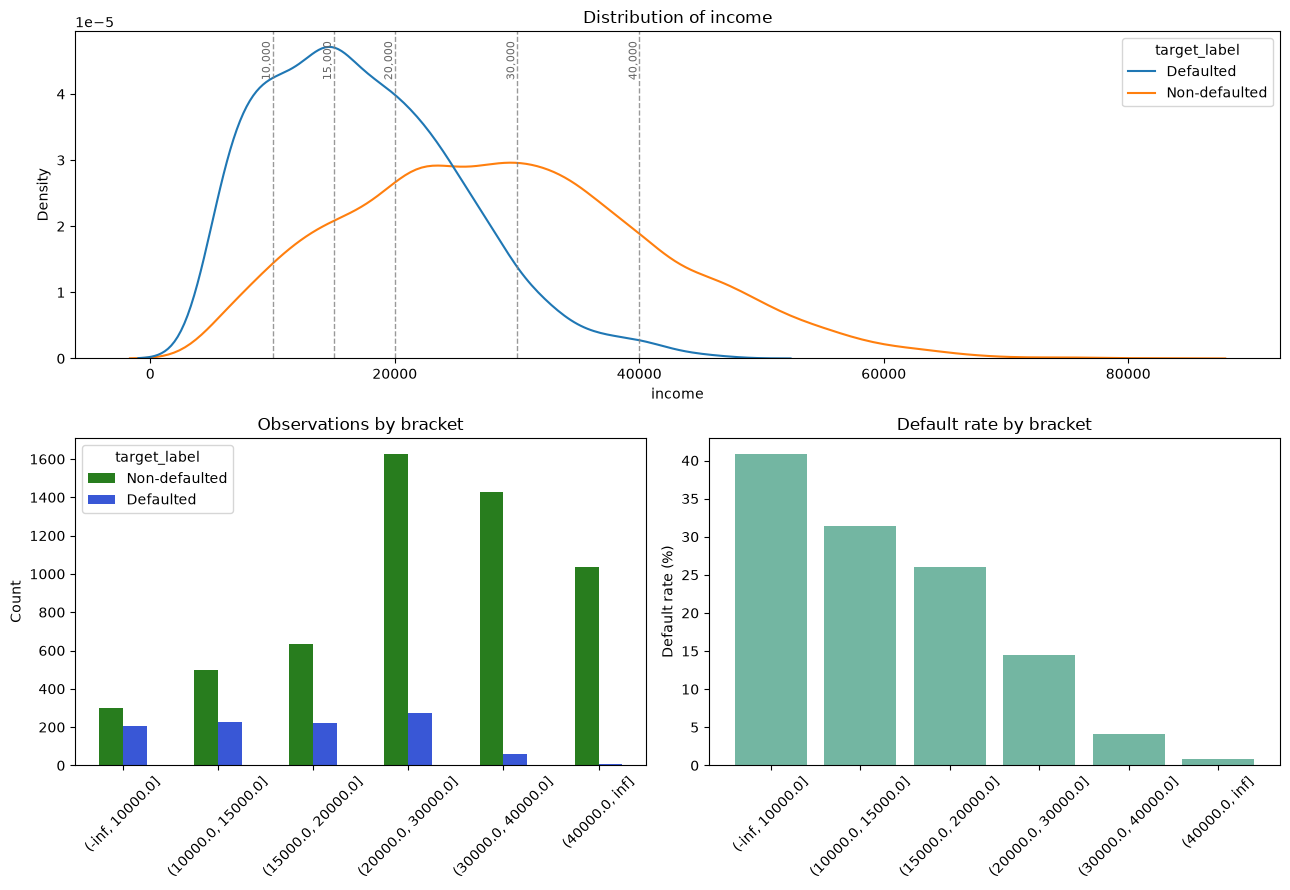

target_label,Non-defaulted,Defaulted,total,default_rate
bracket,,,,
"(-inf, 10000.0]",298,206,504,40.873016
"(10000.0, 15000.0]",498,228,726,31.404959
"(15000.0, 20000.0]",633,222,855,25.964912
"(20000.0, 30000.0]",1627,276,1903,14.503416
"(30000.0, 40000.0]",1428,61,1489,4.096709
"(40000.0, inf]",1036,9,1045,0.861244


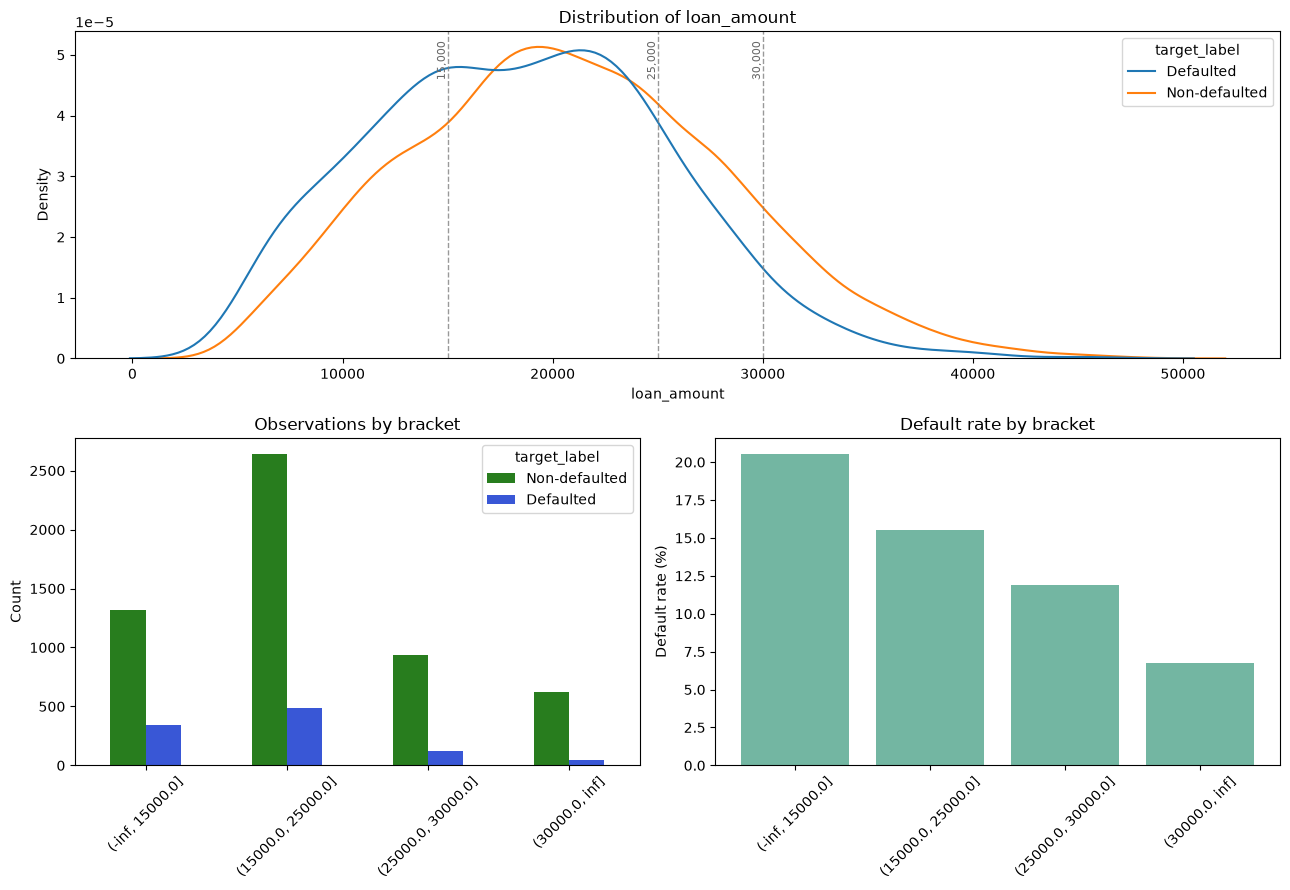

target_label,Non-defaulted,Defaulted,total,default_rate
bracket,,,,
"(-inf, 15000.0]",1315,340,1655,20.543807
"(15000.0, 25000.0]",2642,486,3128,15.537084
"(25000.0, 30000.0]",933,126,1059,11.898017
"(30000.0, inf]",624,45,669,6.726457


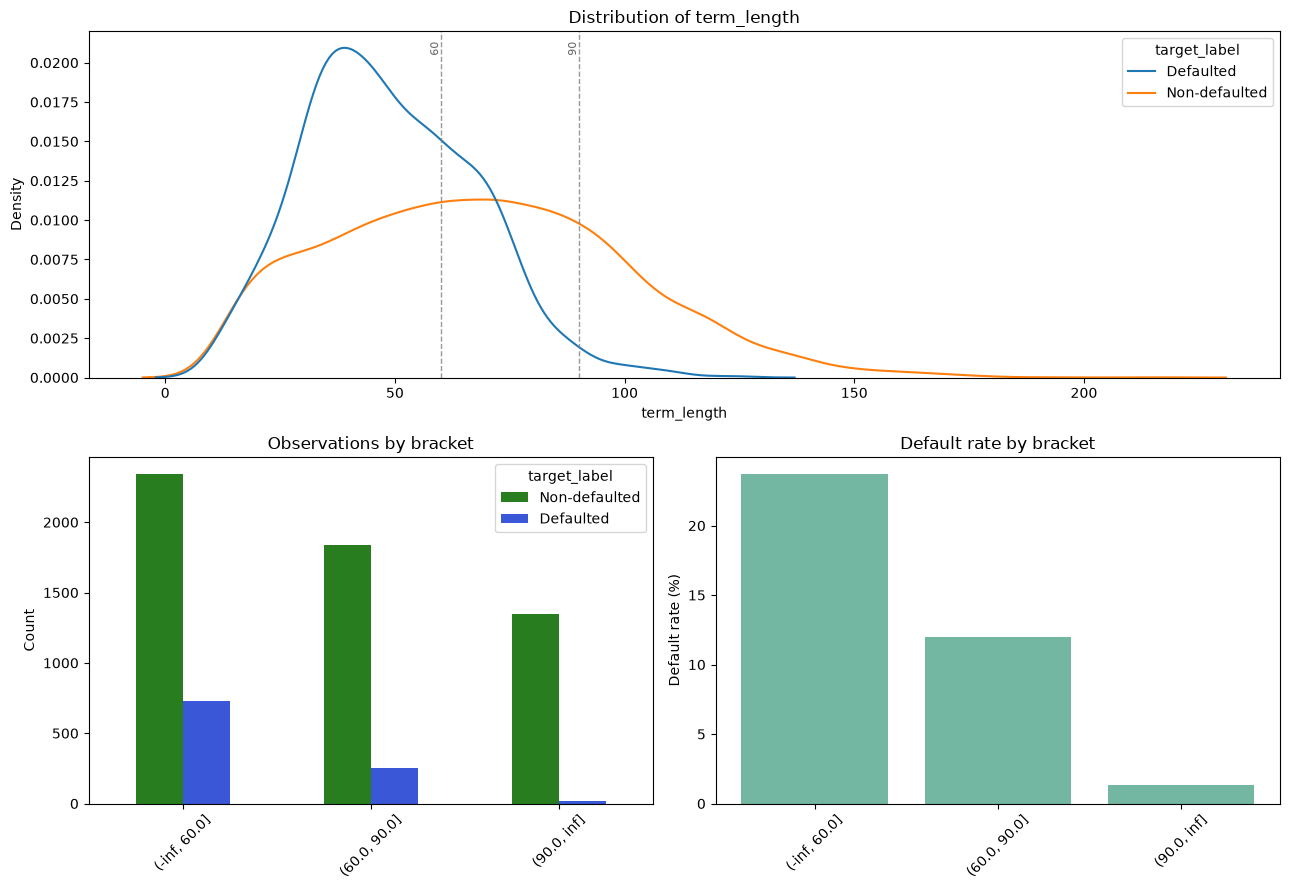

target_label,Non-defaulted,Defaulted,total,default_rate
bracket,,,,
"(-inf, 60.0]",2344,729,3073,23.722747
"(60.0, 90.0]",1835,250,2085,11.990408
"(90.0, inf]",1351,18,1369,1.314828


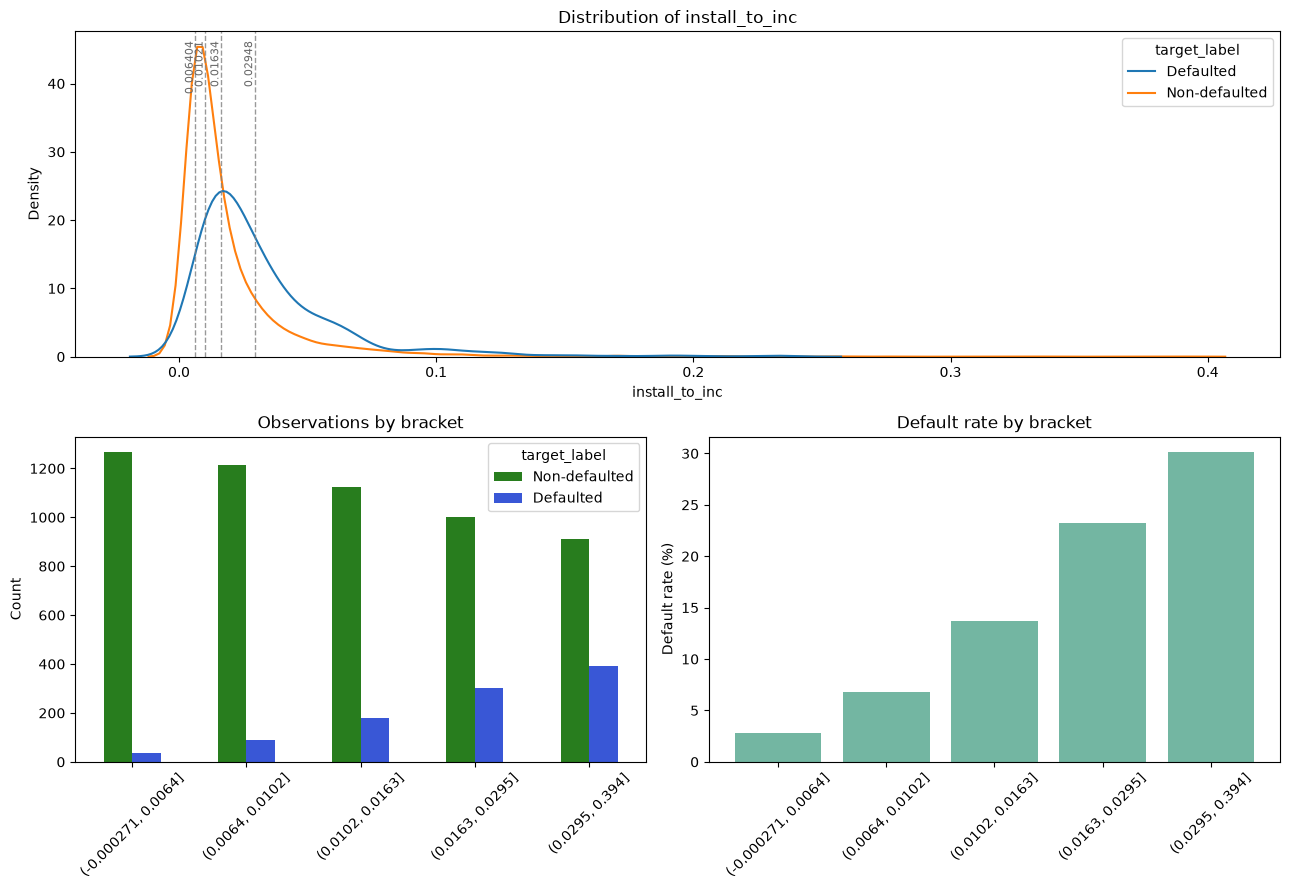

target_label,Non-defaulted,Defaulted,total,default_rate
bracket,,,,
"(-0.000271, 0.0064]",1267,37,1304,2.837423
"(0.0064, 0.0102]",1215,89,1304,6.825153
"(0.0102, 0.0163]",1124,179,1303,13.737529
"(0.0163, 0.0295]",1001,303,1304,23.236196
"(0.0295, 0.394]",911,393,1304,30.138037


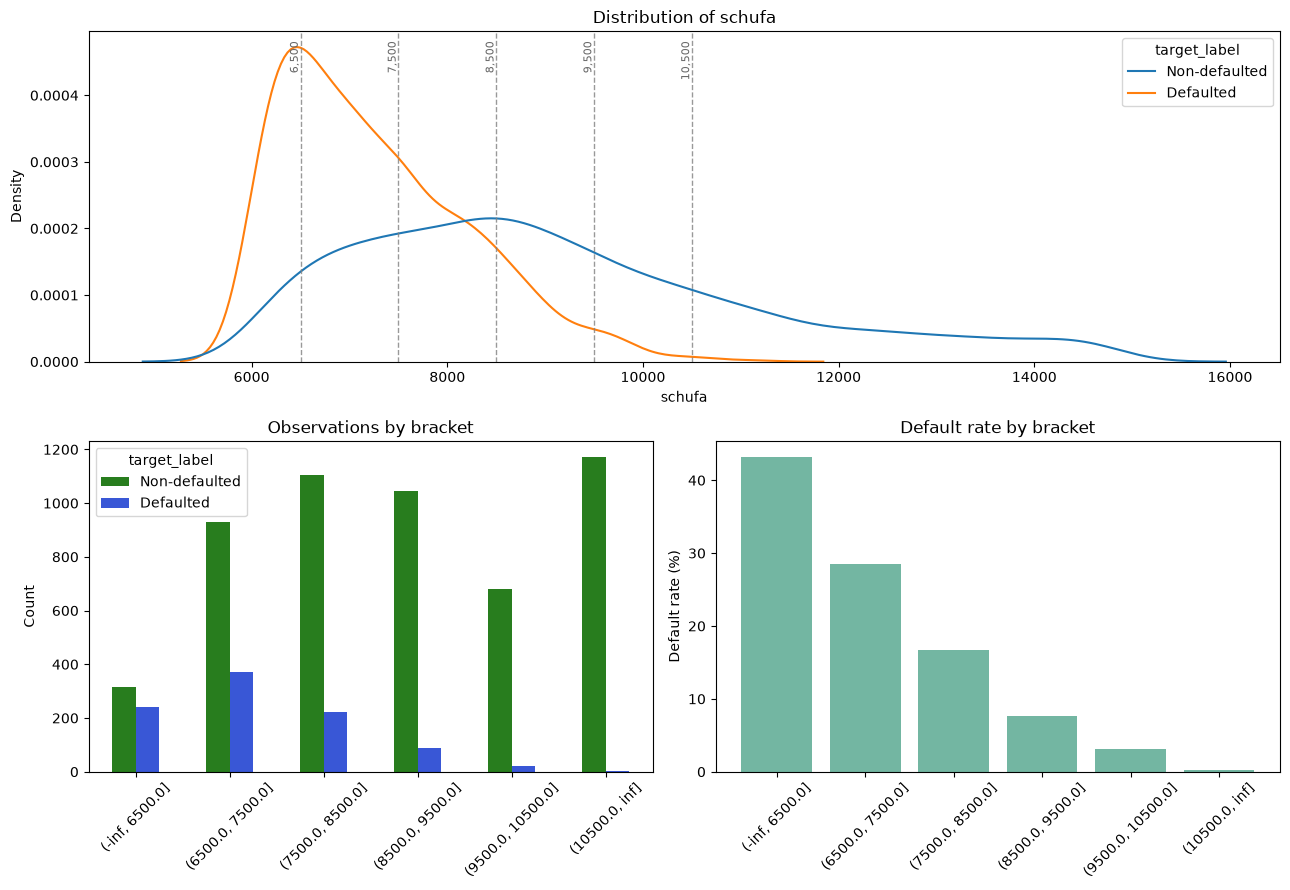

target_label,Non-defaulted,Defaulted,total,default_rate
bracket,,,,
"(-inf, 6500.0]",316,240,556,43.165468
"(6500.0, 7500.0]",928,370,1298,28.505393
"(7500.0, 8500.0]",1103,221,1324,16.691843
"(8500.0, 9500.0]",1045,87,1132,7.685512
"(9500.0, 10500.0]",682,22,704,3.125000
"(10500.0, inf]",1171,3,1174,0.255537


In [28]:
numeric_features = [
    "income",
    "loan_amount",
    "term_length",
    "install_to_inc",
    "schufa"
]

feature_bins = {
    "income": 5,
    "loan_amount": 4,
    "term_length": 4,
    "install_to_inc": 5,
    "schufa": 6
}
feature_bins["loan_amount"] = [
    -float("inf"),
    15_000,
    25_000,
    30_000,
    float("inf")
]
feature_bins["income"] = [
    -float("inf"),
    10_000,
    15_000,
    20_000,
    30_000,
    40_000,
    float("inf")
]
feature_bins["term_length"] = [
    -float("inf"),
    60,
    90,
    float("inf")
]

feature_bins["schufa"] = [
    -float("inf"),
    6_500,
    7_500,
    8_500,
    9_500,
    10_500,
    float("inf")
]

for feature, bins in feature_bins.items():
    figure, summary = plot_numeric_feature(
        train,
        column=feature,
        bins=bins
    )

    plt.show()
    display(summary)

# Outlier and Skewness diagnostics

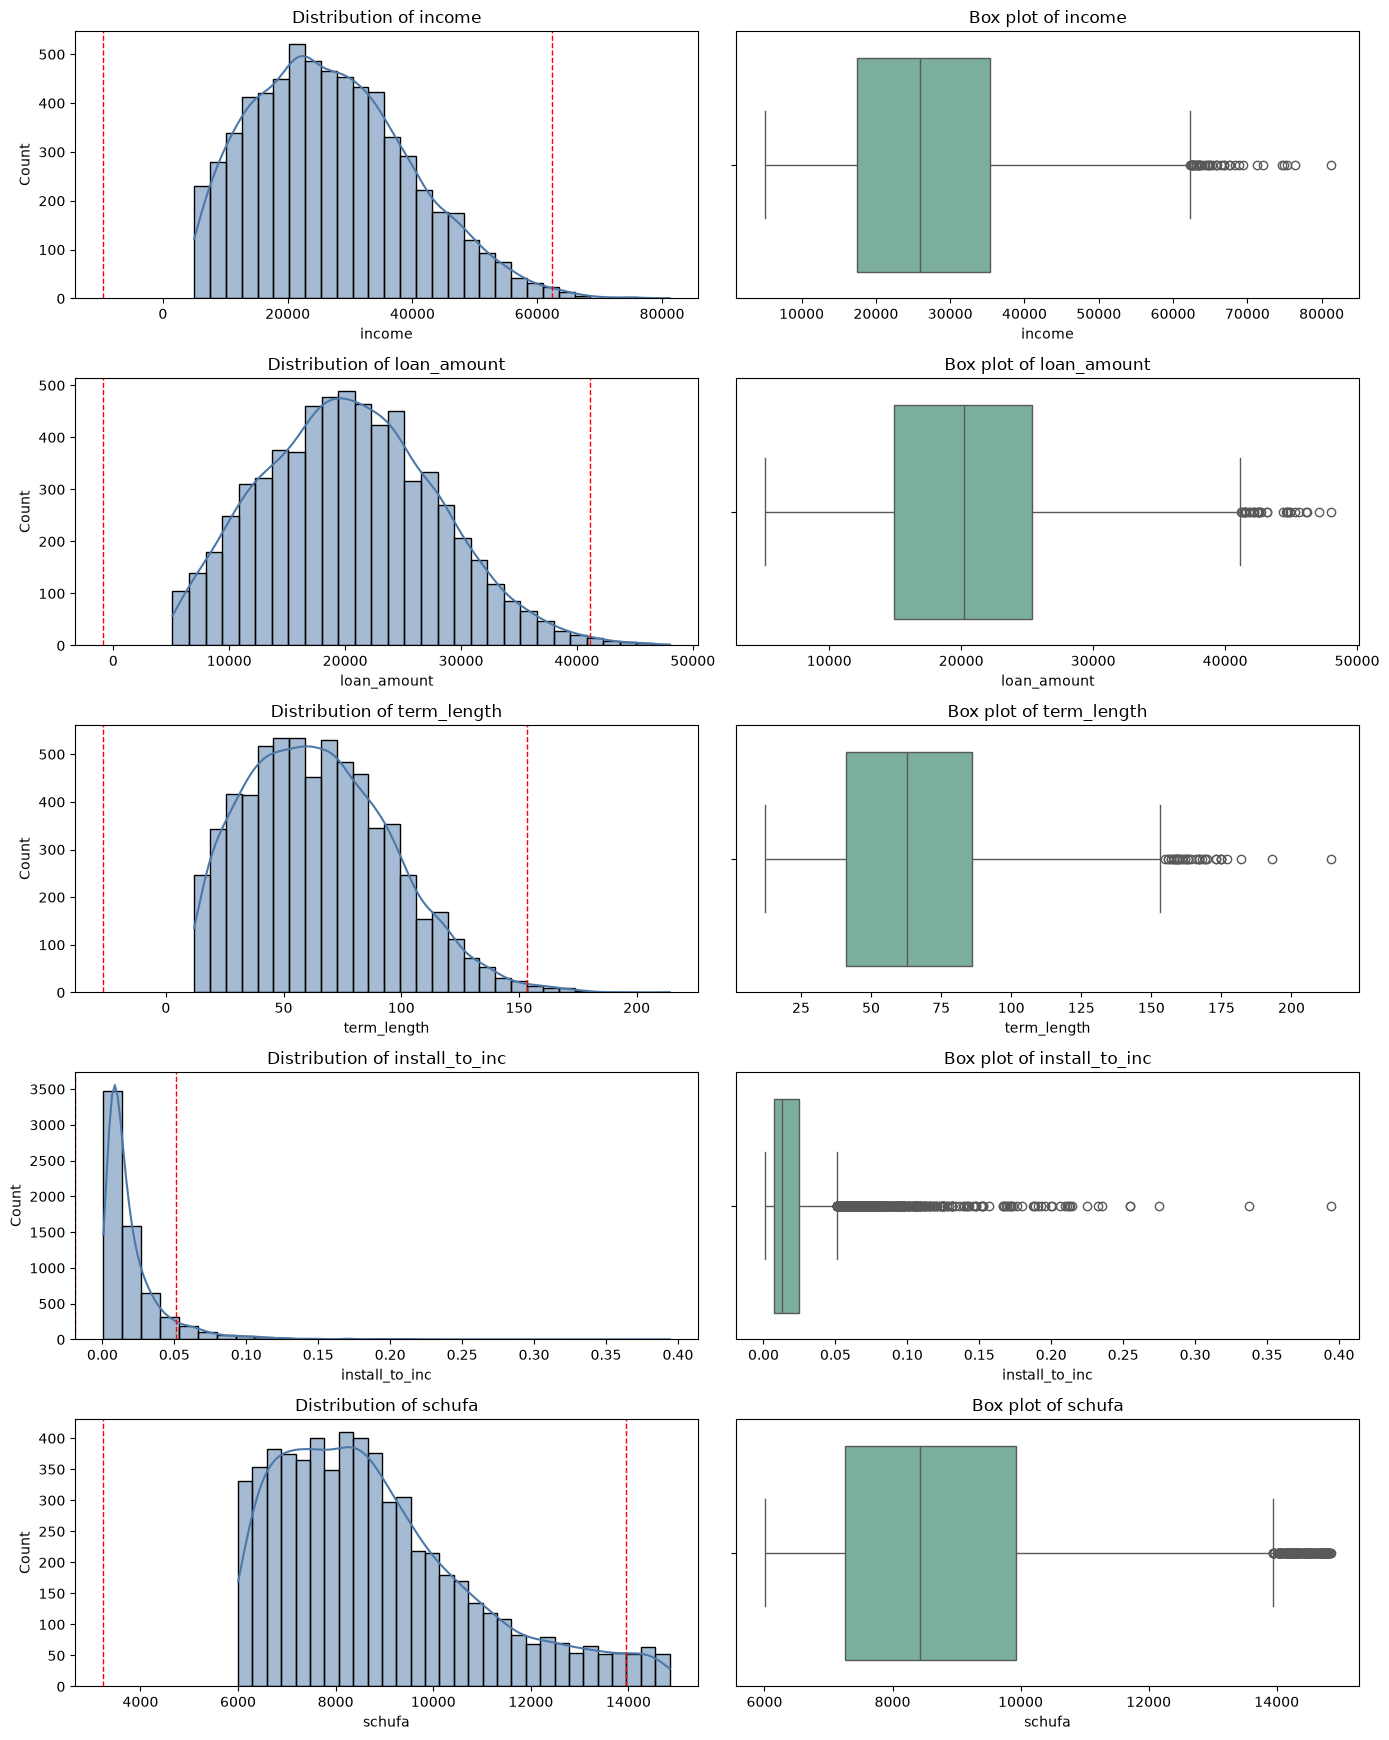

,count,missing,mean,median,skewness,minimum,p01,p99,maximum,iqr_lower_bound,iqr_upper_bound,outlier_count,outlier_pct
feature,,,,,,,,,,,,,
income,6522,65,27120.918,25959.788,0.489,5011.709,5684.384,59494.224,81215.722,-9521.905,62313.007,41,0.629
loan_amount,6511,76,20428.920,20200.000,0.276,5100.000,6100.000,38900.000,48000.000,-850.000,41150.000,33,0.507
term_length,6527,60,65.346,63.000,0.508,12.000,14.000,146.000,214.000,-26.500,153.500,39,0.598
install_to_inc,6519,68,0.021,0.013,4.096,0.001,0.002,0.124,0.394,-0.019,0.051,547,8.391
schufa,6188,399,8841.399,8431.906,0.920,6001.367,6049.361,14519.413,14843.618,3242.510,13940.682,172,2.780


In [30]:
continuous_features = [
    "income",
    "loan_amount",
    "term_length",
    "install_to_inc",
    "schufa"
]

figure, diagnostic_summary = numeric_diagnostics(
    train,
    continuous_features
)

plt.show()
display(diagnostic_summary.round(3))

# install_to_inc transformation

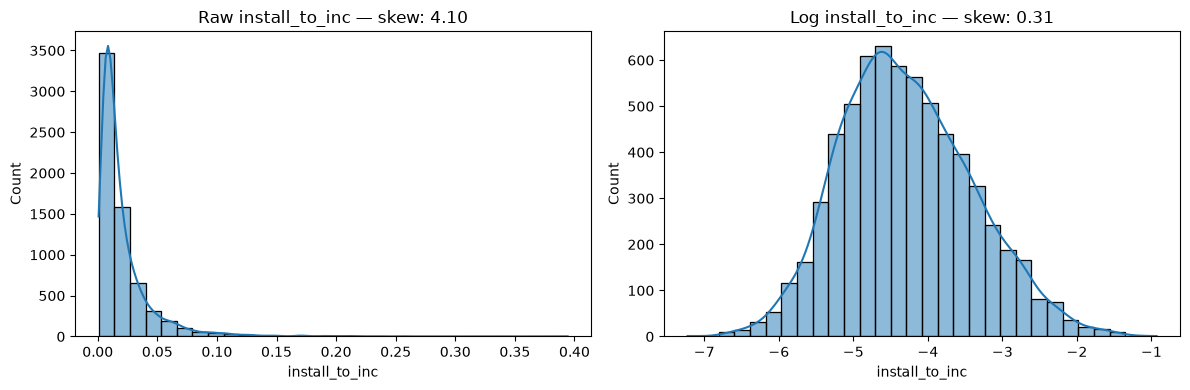

In [31]:
values = pd.to_numeric(
    train["install_to_inc"],
    errors="coerce"
).dropna()

log_values = np.log(values)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(
    values,
    bins=30,
    kde=True,
    ax=axes[0]
)
axes[0].set_title(
    f"Raw install_to_inc — skew: {values.skew():.2f}"
)

sns.histplot(
    log_values,
    bins=30,
    kde=True,
    ax=axes[1]
)
axes[1].set_title(
    f"Log install_to_inc — skew: {log_values.skew():.2f}"
)

plt.tight_layout()
plt.show()

In [32]:
for dataset in (train, test):
    ratio = pd.to_numeric(
        dataset["install_to_inc"],
        errors="coerce"
    )

    invalid_or_missing = (
        ratio.isna()
        | ratio.le(0)
    )

    # Optional candidate feature
    dataset["install_to_inc_missing"] = (
        invalid_or_missing.astype("int8")
    )

    # Keep the original column and add the transformed version
    dataset["install_to_inc_log"] = np.log(
        ratio.where(~invalid_or_missing)
    )

In [33]:
install_summary = pd.DataFrame({
    "train": [
        train["install_to_inc"].isna().sum(),
        train["install_to_inc"].le(0).sum(),
        train["install_to_inc_log"].isna().sum()
    ],
    "test": [
        test["install_to_inc"].isna().sum(),
        test["install_to_inc"].le(0).sum(),
        test["install_to_inc_log"].isna().sum()
    ]
}, index=[
    "original_nulls",
    "non_positive_values",
    "log_nulls"
])

install_summary

,train,test
original_nulls,68,20
non_positive_values,0,0
log_nulls,68,20


# Income transformation

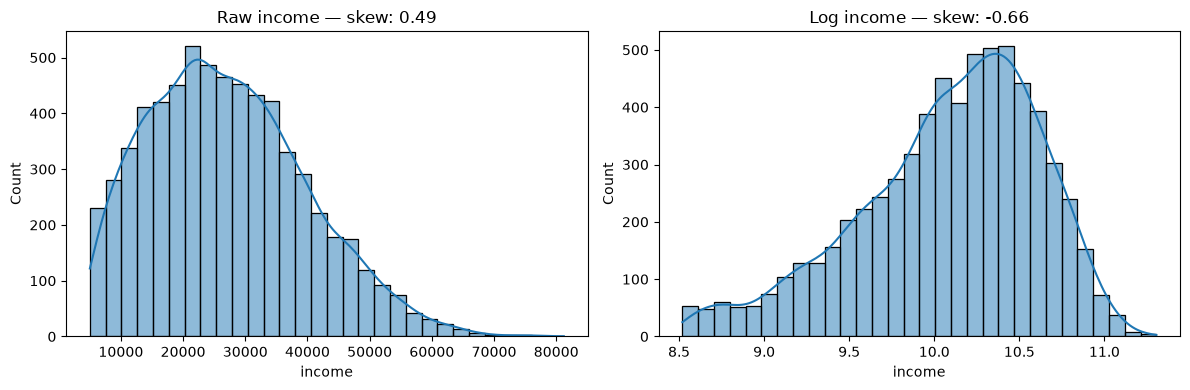

In [40]:
values = pd.to_numeric(
    train["income"],
    errors="coerce"
).dropna()

log_values = np.log(values)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(
    values,
    bins=30,
    kde=True,
    ax=axes[0]
)
axes[0].set_title(
    f"Raw income — skew: {values.skew():.2f}"
)

sns.histplot(
    log_values,
    bins=30,
    kde=True,
    ax=axes[1]
)
axes[1].set_title(
    f"Log income — skew: {log_values.skew():.2f}"
)

plt.tight_layout()
plt.show()

**no need to create log variable - original skewness is better**

In [37]:
income_bins = [
    -float("inf"),
    10_000,
    15_000,
    20_000,
    30_000,
    40_000,
    float("inf")
]

income_labels = [
    "Up to 10000",
    "10000-15000",
    "15000-20000",
    "20000-30000",
    "30000-40000",
    "Above 40000"
]

for dataset in (train, test):
    income = pd.to_numeric(
        dataset["income"],
        errors="coerce"
    )

    invalid_or_missing = (
        income.isna()
        | income.le(0)
    )

    # Candidate missingness feature
    dataset["income_missing"] = (
        invalid_or_missing.astype("int8")
    )

    # Categorical candidate
    dataset["income_bracket"] = (
        pd.cut(
            income,
            bins=income_bins,
            labels=income_labels
        )
        .astype("string")
        .fillna("Missing")
    )

In [39]:
income_summary = pd.DataFrame({
    "train": [
        train["income"].isna().sum(),
        train["income"].le(0).sum(),
        train["income_bracket"].eq("Missing").sum()
    ],
    "test": [
        test["income"].isna().sum(),
        test["income"].le(0).sum(),
        test["income_bracket"].eq("Missing").sum()
    ]
}, index=[
    "original_nulls",
    "non_positive_values",
    "missing_brackets"
])

income_summary

,train,test
original_nulls,65,22
non_positive_values,0,0
missing_brackets,65,22


# loan_amount transformation

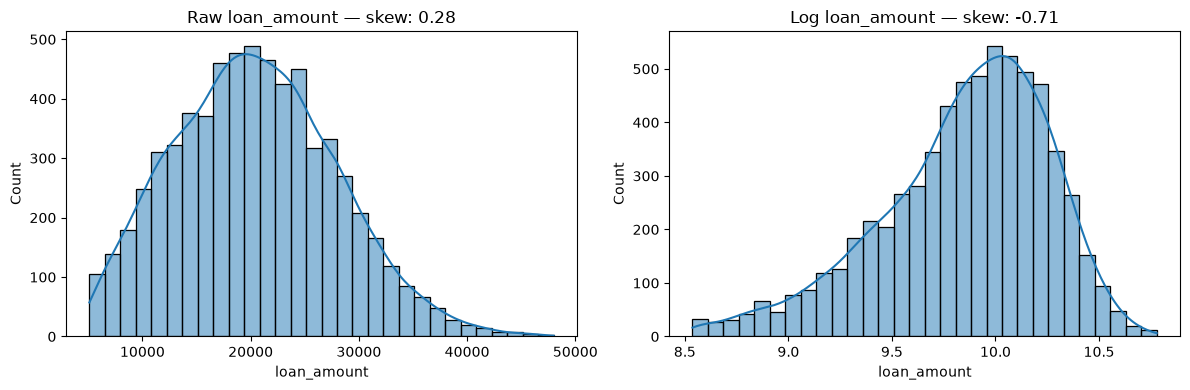

In [45]:
values = pd.to_numeric(
    train["loan_amount"],
    errors="coerce"
).dropna()

log_values = np.log(values)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(
    values,
    bins=30,
    kde=True,
    ax=axes[0]
)
axes[0].set_title(
    f"Raw loan_amount — skew: {values.skew():.2f}"
)

sns.histplot(
    log_values,
    bins=30,
    kde=True,
    ax=axes[1]
)
axes[1].set_title(
    f"Log loan_amount — skew: {log_values.skew():.2f}"
)

plt.tight_layout()
plt.show()

**no need to create log variable - original skewness is better**

In [41]:
loan_amount_bins = [
    -float("inf"),
    15_000,
    25_000,
    30_000,
    float("inf")
]

loan_amount_labels = [
    "Up to 15000",
    "15000-25000",
    "25000-30000",
    "Above 30000"
]

for dataset in (train, test):
    loan_amount = pd.to_numeric(
        dataset["loan_amount"],
        errors="coerce"
    )

    invalid_or_missing = (
        loan_amount.isna()
        | loan_amount.le(0)
    )

    dataset["loan_amount_missing"] = (
        invalid_or_missing.astype("int8")
    )

    dataset["loan_amount_bracket"] = (
        pd.cut(
            loan_amount,
            bins=loan_amount_bins,
            labels=loan_amount_labels
        )
        .astype("string")
        .fillna("Missing")
    )

In [42]:
loan_amount_summary = pd.DataFrame({
    "train": [
        train["loan_amount"].isna().sum(),
        train["loan_amount"].le(0).sum(),
        train["loan_amount_bracket"].eq("Missing").sum()
    ],
    "test": [
        test["loan_amount"].isna().sum(),
        test["loan_amount"].le(0).sum(),
        test["loan_amount_bracket"].eq("Missing").sum()
    ]
}, index=[
    "original_nulls",
    "non_positive_values",
    "missing_brackets"
])

loan_amount_summary

,train,test
original_nulls,76,25
non_positive_values,0,0
missing_brackets,76,25


# term_length transformation

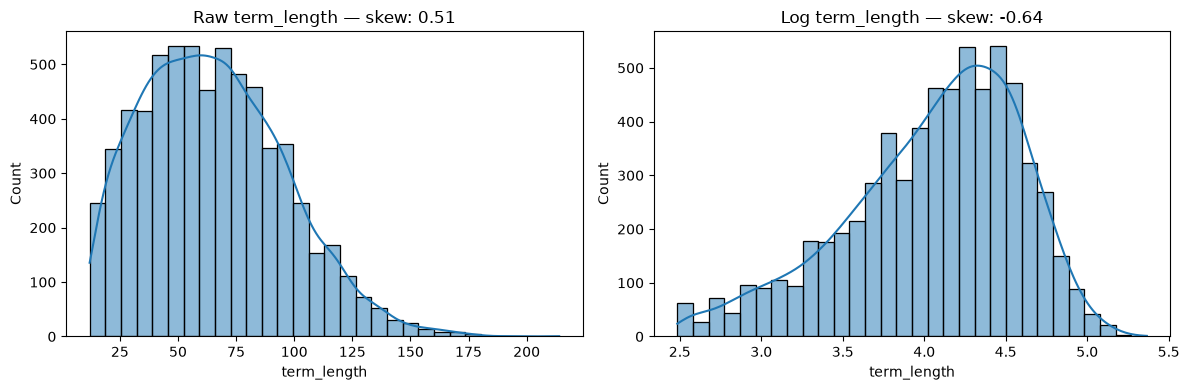

In [46]:
values = pd.to_numeric(
    train["term_length"],
    errors="coerce"
).dropna()

log_values = np.log(values)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(
    values,
    bins=30,
    kde=True,
    ax=axes[0]
)
axes[0].set_title(
    f"Raw term_length — skew: {values.skew():.2f}"
)

sns.histplot(
    log_values,
    bins=30,
    kde=True,
    ax=axes[1]
)
axes[1].set_title(
    f"Log term_length — skew: {log_values.skew():.2f}"
)

plt.tight_layout()
plt.show()

**no need to create log variable - original skewness is better**

In [48]:
term_length_bins = [
    -float("inf"),
    60,
    90,
    float("inf")
]

term_length_labels = [
    "Up to 60 months",
    "60-90 months",
    "Above 90 months"
]

for dataset in (train, test):
    term_length = pd.to_numeric(
        dataset["term_length"],
        errors="coerce"
    )

    invalid_or_missing = (
        term_length.isna()
        | term_length.le(0)
    )

    dataset["term_length_missing"] = (
        invalid_or_missing.astype("int8")
    )

    dataset["term_length_bracket"] = (
        pd.cut(
            term_length,
            bins=term_length_bins,
            labels=term_length_labels
        )
        .astype("string")
        .fillna("Missing")
    )

In [49]:
term_length_summary = pd.DataFrame({
    "train": [
        train["term_length"].isna().sum(),
        train["term_length"].le(0).sum(),
        train["term_length_bracket"].eq("Missing").sum()
    ],
    "test": [
        test["term_length"].isna().sum(),
        test["term_length"].le(0).sum(),
        test["term_length_bracket"].eq("Missing").sum()
    ]
}, index=[
    "original_nulls",
    "non_positive_values",
    "missing_brackets"
])

term_length_summary

,train,test
original_nulls,60,22
non_positive_values,0,0
missing_brackets,60,22


# SCHUFA transformation

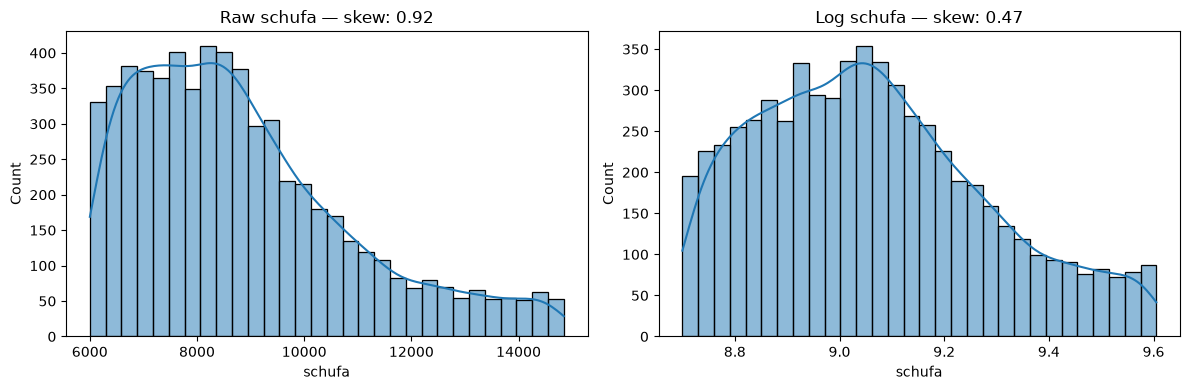

In [53]:
values = pd.to_numeric(
    train["schufa"],
    errors="coerce"
).dropna()

log_values = np.log(values)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(
    values,
    bins=30,
    kde=True,
    ax=axes[0]
)
axes[0].set_title(
    f"Raw schufa — skew: {values.skew():.2f}"
)

sns.histplot(
    log_values,
    bins=30,
    kde=True,
    ax=axes[1]
)
axes[1].set_title(
    f"Log schufa — skew: {log_values.skew():.2f}"
)

plt.tight_layout()
plt.show()

In [54]:
schufa_bins = [
    -float("inf"),
    6_500,
    7_500,
    8_500,
    9_500,
    10_500,
    float("inf")
]

schufa_labels = [
    "Up to 6500",
    "6500-7500",
    "7500-8500",
    "8500-9500",
    "9500-10500",
    "Above 10500"
]


for dataset in (train, test):
    schufa = pd.to_numeric(
        dataset["schufa"],
        errors="coerce"
    )

    invalid_or_missing = (
        schufa.isna()
        | schufa.le(0)
    )

    dataset["schufa_missing"] = (
        invalid_or_missing.astype("int8")
    )

    dataset["schufa_log"] = np.log(
        schufa.where(~invalid_or_missing)
    )

    dataset["schufa_bracket"] = (
        pd.cut(
            schufa,
            bins=schufa_bins,
            labels=schufa_labels
        )
        .astype("string")
        .fillna("Missing")
    )
    )

In [58]:
schufa_summary = pd.DataFrame({
    "train": [
        train["schufa"].isna().sum(),
        train["schufa"].le(0).sum(),
        train["schufa_log"].isna().sum(),
        train["schufa_bracket"].eq("Missing").sum()
    ],
    "test": [
        test["schufa"].isna().sum(),
        test["schufa"].le(0).sum(),
        test["schufa_log"].isna().sum(),
        test["schufa_bracket"].eq("Missing").sum()
    ]
}, index=[
    "original_nulls",
    "non_positive_values",
    "log_nulls",
    "missing_brackets"
])

schufa_summary

,train,test
original_nulls,399,120
non_positive_values,0,0
log_nulls,399,120
missing_brackets,399,120


# One-hot-Encoding bracket columns

In [60]:
bracket_columns = [
    "income_bracket",
    "loan_amount_bracket",
    "term_length_bracket",
    "schufa_bracket"
]

X_correlation = train.drop(
    columns=["target_var", "OBS_DATE"],
    errors="ignore"
).copy()

# Ensure missing brackets remain an explicit category
for column in bracket_columns:
    X_correlation[column] = (
        X_correlation[column]
        .astype("string")
        .fillna("Missing")
    )

# Temporary encoding—does not modify train
X_correlation = pd.get_dummies(
    X_correlation,
    columns=bracket_columns,
    dtype=float
)

non_numeric_columns = X_correlation.select_dtypes(
    exclude="number"
).columns.tolist()

print("Non-numeric columns remaining:", non_numeric_columns)
print("Features included:", X_correlation.shape[1])

Non-numeric columns remaining: []
Features included: 51


# Correlation Matrix

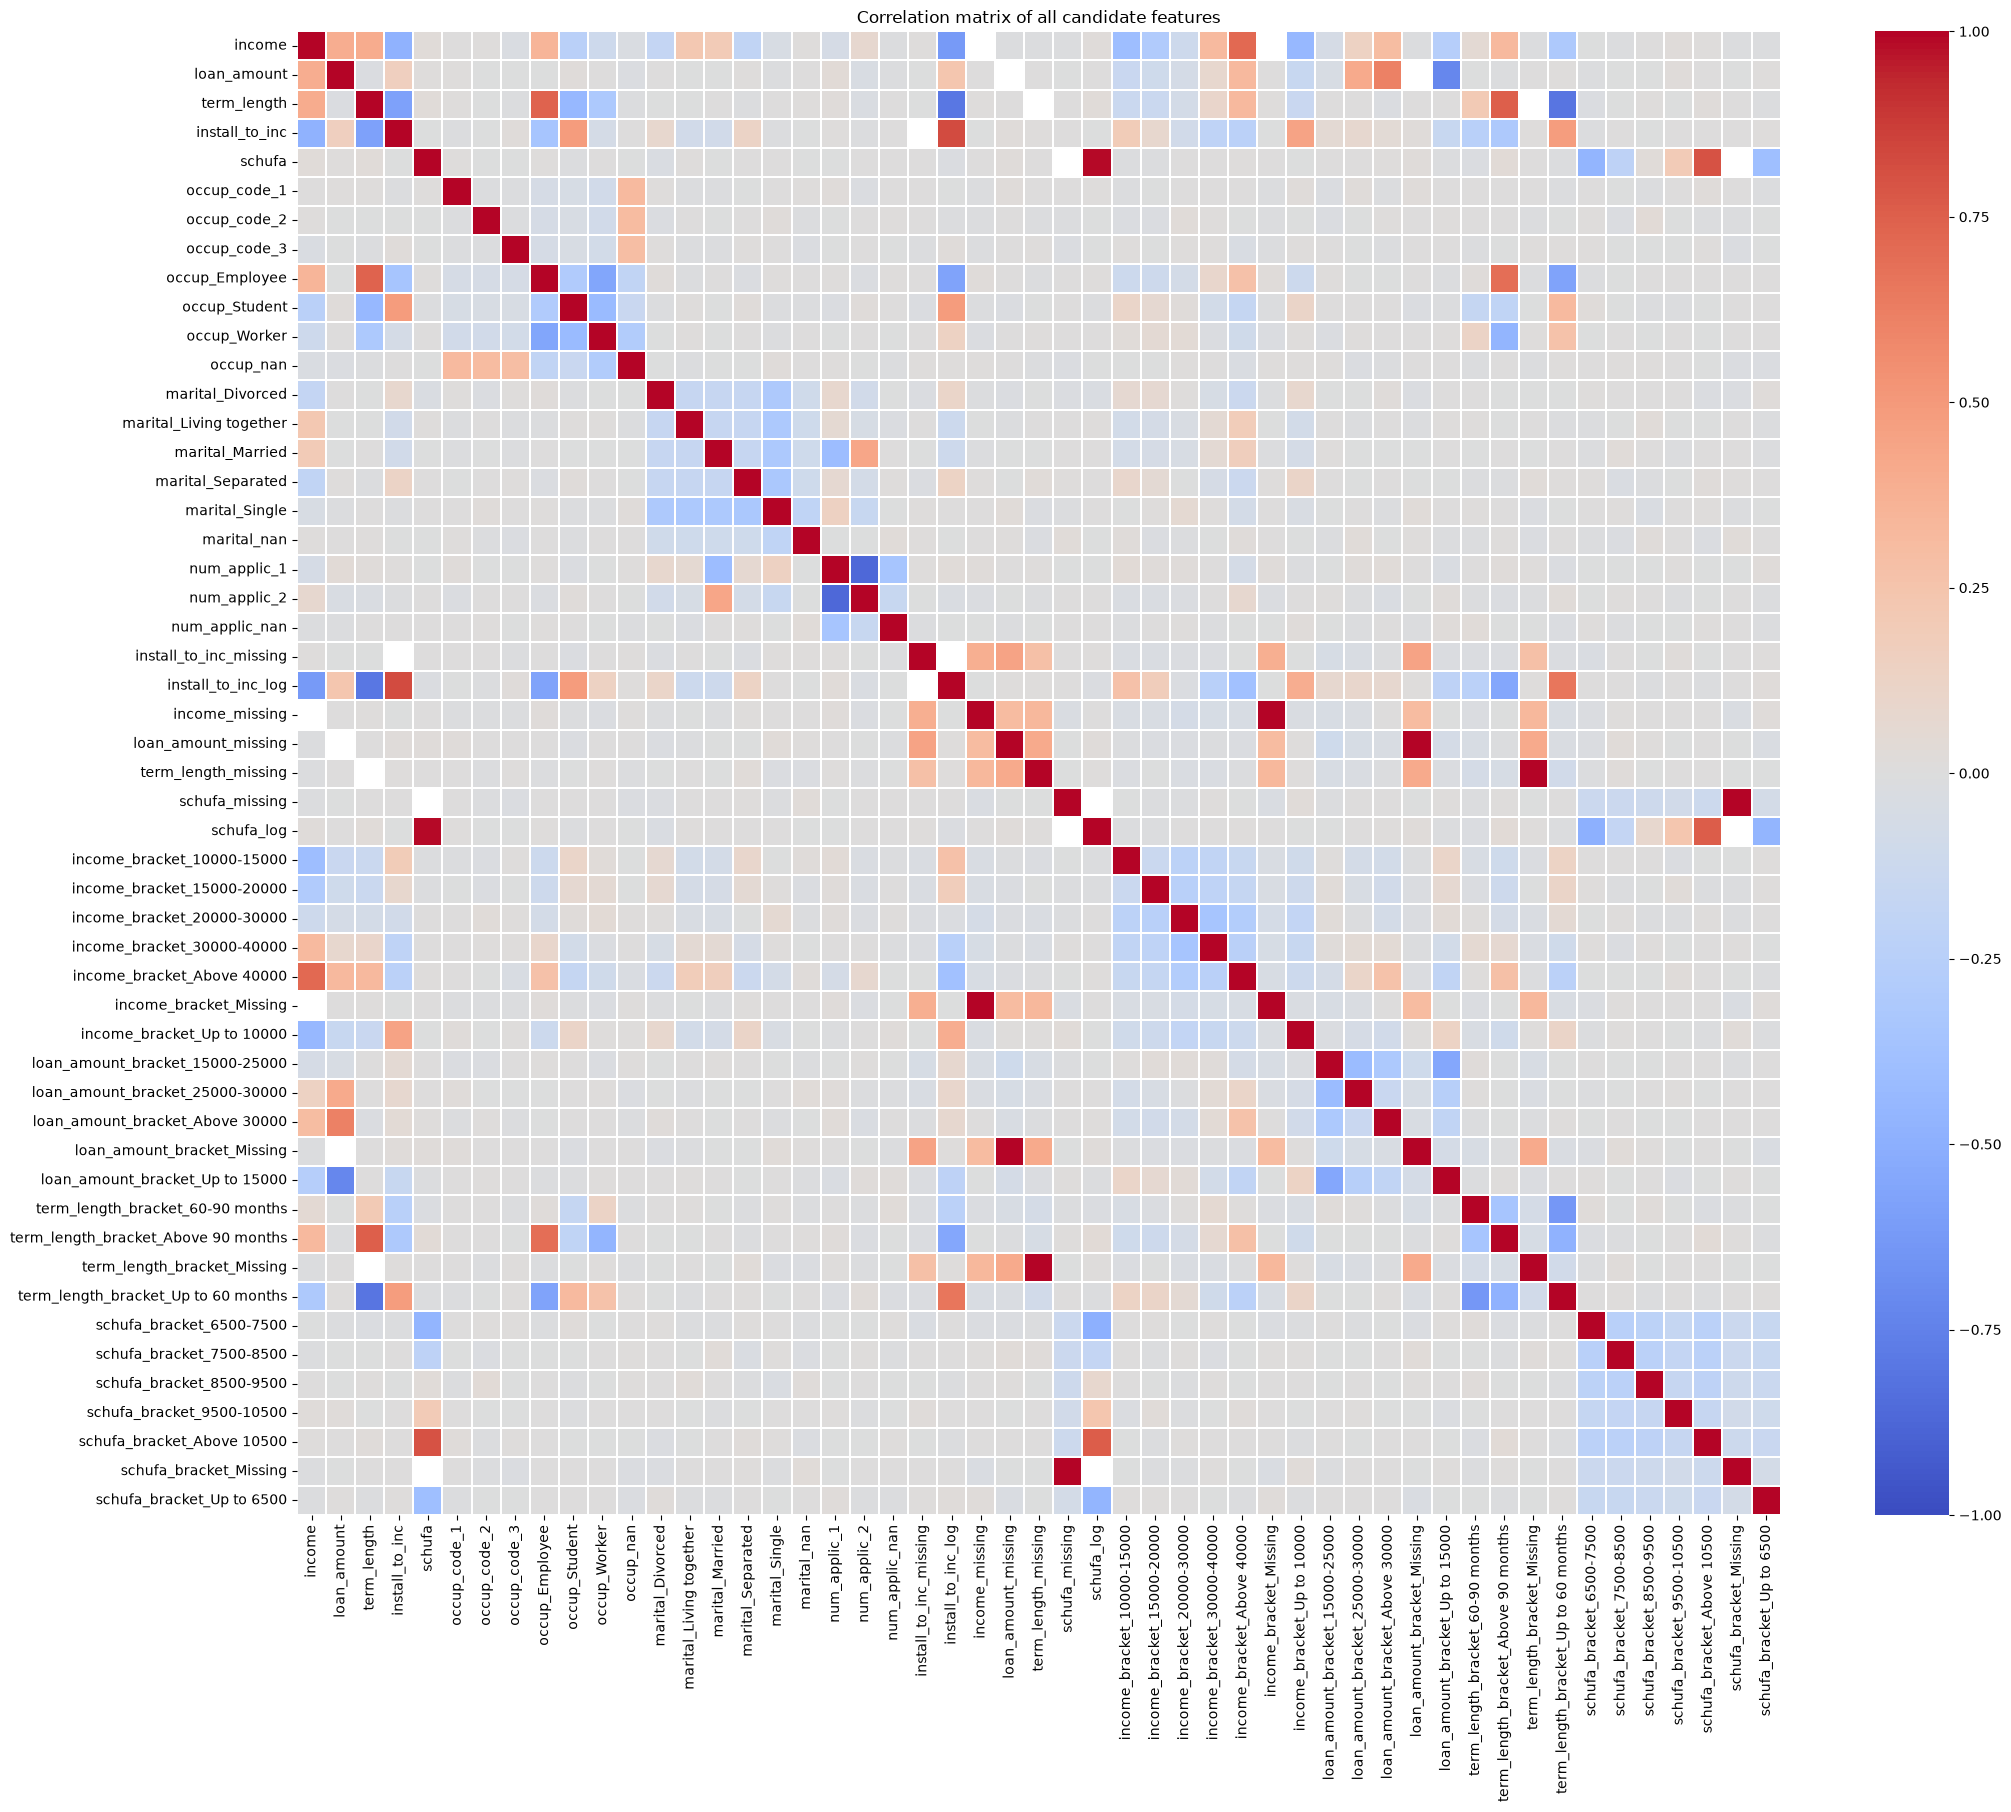

In [61]:
all_feature_corr = X_correlation.corr(method="pearson")

plt.figure(figsize=(22, 18))

sns.heatmap(
    all_feature_corr,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.15
)

plt.title("Correlation matrix of all candidate features")
plt.tight_layout()
plt.show()

In [62]:
upper_triangle = all_feature_corr.where(
    np.triu(
        np.ones(all_feature_corr.shape, dtype=bool),
        k=1
    )
)

high_correlation_pairs = (
    upper_triangle
    .stack()
    .rename("correlation")
    .reset_index()
    .rename(columns={
        "level_0": "feature_1",
        "level_1": "feature_2"
    })
)

high_correlation_pairs["absolute_correlation"] = (
    high_correlation_pairs["correlation"].abs()
)

high_correlation_pairs = (
    high_correlation_pairs
    .query("absolute_correlation >= 0.80")
    .sort_values("absolute_correlation", ascending=False)
    .reset_index(drop=True)
)

high_correlation_pairs

,feature_1,feature_2,correlation,absolute_correlation
0,income_missing,income_bracket_Missing,1.000000,1.000000
1,loan_amount_missing,loan_amount_bracket_Missing,1.000000,1.000000
2,term_length_missing,term_length_bracket_Missing,1.000000,1.000000
3,schufa_missing,schufa_bracket_Missing,1.000000,1.000000
4,schufa,schufa_log,0.992000,0.992000
5,num_applic_1,num_applic_2,-0.874389,0.874389
6,install_to_inc,install_to_inc_log,0.823981,0.823981
7,term_length,term_length_bracket_Up to 60 months,-0.806075,0.806075
8,schufa,schufa_bracket_Above 10500,0.804625,0.804625
9,term_length,install_to_inc_log,-0.802200,0.802200


**Corresponding missing columns will be chosen whether model fit run is with brackets or continuous (or just 1 will be chosen if both)**

In [65]:
from pathlib import Path

data_folder = "../data/"

train_output_path = data_folder + "train_feature_engineered_v1.csv"
test_output_path = data_folder + "test_feature_engineered_v1.csv"

train.to_csv(
    train_output_path,
    index=False,
    date_format="%Y-%m-%d"
)

test.to_csv(
    test_output_path,
    index=False,
    date_format="%Y-%m-%d"
)

print("Saved train:", train_output_path)
print("Saved test: ", test_output_path)

Saved train: ../data/train_feature_engineered_v1.csv
Saved test:  ../data/test_feature_engineered_v1.csv


In [66]:
saved_train = pd.read_csv(
    train_output_path,
    parse_dates=["OBS_DATE"]
)

saved_test = pd.read_csv(
    test_output_path,
    parse_dates=["OBS_DATE"]
)

save_check = pd.DataFrame({
    "original_rows": [len(train), len(test)],
    "saved_rows": [len(saved_train), len(saved_test)],
    "original_columns": [train.shape[1], test.shape[1]],
    "saved_columns": [saved_train.shape[1], saved_test.shape[1]]
}, index=["train", "test"])

save_check

,original_rows,saved_rows,original_columns,saved_columns
train,6587,6587,34,34
test,2314,2314,34,34


# Visuals

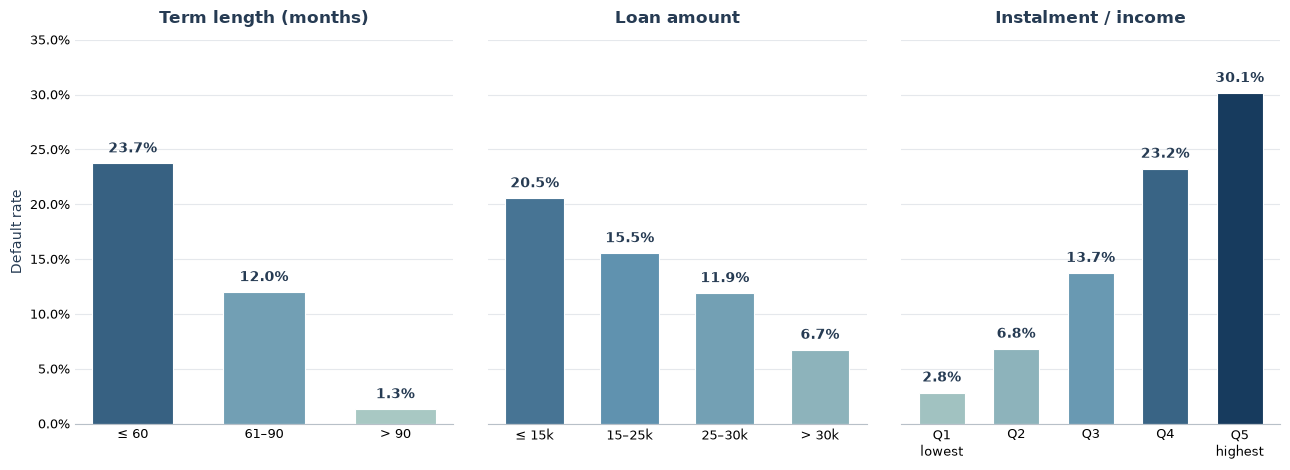

In [68]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from matplotlib.colors import LinearSegmentedColormap, Normalize

plot_data = train[
    [
        "target_var",
        "term_length",
        "loan_amount",
        "install_to_inc"
    ]
].copy()

plot_data["term_bucket"] = pd.cut(
    plot_data["term_length"],
    bins=[-np.inf, 60, 90, np.inf],
    labels=["≤ 60", "61–90", "> 90"]
)

plot_data["loan_bucket"] = pd.cut(
    plot_data["loan_amount"],
    bins=[-np.inf, 15_000, 25_000, 30_000, np.inf],
    labels=["≤ 15k", "15–25k", "25–30k", "> 30k"]
)

plot_data["instalment_bucket"] = pd.qcut(
    plot_data["install_to_inc"],
    q=5,
    labels=["Q1\nlowest", "Q2", "Q3", "Q4", "Q5\nhighest"]
)

term_rates = (
    plot_data.groupby("term_bucket", observed=False)["target_var"]
    .mean()
    .mul(100)
)

loan_rates = (
    plot_data.groupby("loan_bucket", observed=False)["target_var"]
    .mean()
    .mul(100)
)

instalment_rates = (
    plot_data.groupby("instalment_bucket", observed=False)["target_var"]
    .mean()
    .mul(100)
)

charts = [
    ("Term length (months)", term_rates),
    ("Loan amount", loan_rates),
    ("Instalment / income", instalment_rates)
]

all_rates = np.concatenate([
    term_rates.values,
    loan_rates.values,
    instalment_rates.values
])

risk_scale = Normalize(
    vmin=all_rates.min(),
    vmax=all_rates.max()
)

risk_colours = LinearSegmentedColormap.from_list(
    "risk_colours",
    [
        "#A8C8C3",
        "#5F91AF",
        "#173B5E"
    ]
)

text_colour = "#263B53"
grid_colour = "#E5E8EC"

fig, axes = plt.subplots(
    1,
    3,
    figsize=(13, 4.8),
    sharey=True
)

for ax, (title, rates) in zip(axes, charts):
    bar_colours = [
        risk_colours(risk_scale(value))
        for value in rates.values
    ]

    bars = ax.bar(
        rates.index.astype(str),
        rates.values,
        color=bar_colours,
        edgecolor="#FFFFFF",
        linewidth=0.8,
        width=0.62
    )

    for bar, value in zip(bars, rates.values):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            value + 0.7,
            f"{value:.1f}%",
            ha="center",
            va="bottom",
            fontsize=10,
            fontweight="bold",
            color=text_colour
        )

    ax.set_title(
        title,
        fontsize=12,
        fontweight="bold",
        color=text_colour,
        pad=12
    )

    ax.set_ylim(0, 35)
    ax.yaxis.set_major_formatter(PercentFormatter(100))
    ax.yaxis.grid(True, color=grid_colour, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(axis="x", length=0, labelsize=9)
    ax.tick_params(axis="y", length=0, labelsize=9)

    for spine in ["top", "right", "left"]:
        ax.spines[spine].set_visible(False)

    ax.spines["bottom"].set_color("#B8C0C8")

axes[0].set_ylabel(
    "Default rate",
    fontsize=10,
    color=text_colour
)

plt.tight_layout(w_pad=2.5)

fig.savefig(
    "feature_default_rates.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

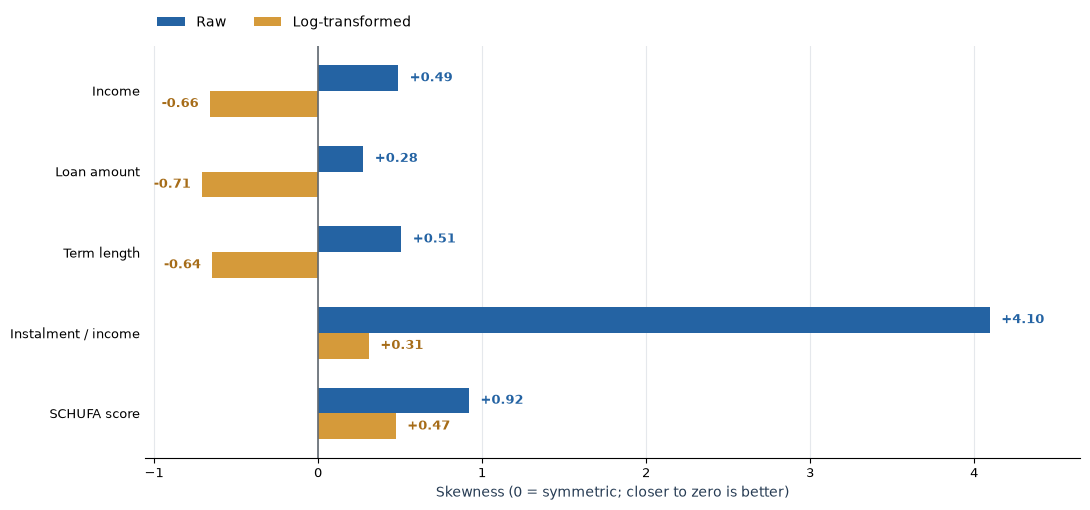

In [69]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

features = [
    "income",
    "loan_amount",
    "term_length",
    "install_to_inc",
    "schufa"
]

feature_labels = {
    "income": "Income",
    "loan_amount": "Loan amount",
    "term_length": "Term length",
    "install_to_inc": "Instalment / income",
    "schufa": "SCHUFA score"
}

skewness_results = []

for feature in features:
    values = pd.to_numeric(
        train[feature],
        errors="coerce"
    ).dropna()

    positive_values = values[values > 0]

    skewness_results.append({
        "feature": feature_labels[feature],
        "raw_skewness": values.skew(),
        "log_skewness": np.log(positive_values).skew()
    })

skewness_data = pd.DataFrame(skewness_results)

y = np.arange(len(skewness_data))
bar_height = 0.32

raw_colour = "#2463A3"
log_colour = "#D59A3A"
text_colour = "#263B53"
grid_colour = "#E5E8EC"

fig, ax = plt.subplots(figsize=(11, 5.2))

raw_bars = ax.barh(
    y - bar_height / 2,
    skewness_data["raw_skewness"],
    height=bar_height,
    color=raw_colour,
    label="Raw"
)

log_bars = ax.barh(
    y + bar_height / 2,
    skewness_data["log_skewness"],
    height=bar_height,
    color=log_colour,
    label="Log-transformed"
)

def add_labels(bars, values, colour):
    for bar, value in zip(bars, values):
        offset = 0.07

        ax.text(
            value + offset if value >= 0 else value - offset,
            bar.get_y() + bar.get_height() / 2,
            f"{value:+.2f}",
            ha="left" if value >= 0 else "right",
            va="center",
            fontsize=9,
            fontweight="bold",
            color=colour
        )

add_labels(
    raw_bars,
    skewness_data["raw_skewness"],
    raw_colour
)

add_labels(
    log_bars,
    skewness_data["log_skewness"],
    "#A66C18"
)

ax.set_yticks(y)
ax.set_yticklabels(skewness_data["feature"])
ax.invert_yaxis()

ax.axvline(
    0,
    color="#606870",
    linewidth=1.2
)

ax.set_xlabel(
    "Skewness (0 = symmetric; closer to zero is better)",
    fontsize=10,
    color=text_colour
)

ax.xaxis.grid(
    True,
    color=grid_colour,
    linewidth=0.8
)
ax.set_axisbelow(True)

minimum_value = min(
    skewness_data["raw_skewness"].min(),
    skewness_data["log_skewness"].min()
)

maximum_value = max(
    skewness_data["raw_skewness"].max(),
    skewness_data["log_skewness"].max()
)

ax.set_xlim(
    minimum_value - 0.35,
    maximum_value + 0.55
)

for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)

ax.tick_params(axis="y", length=0)
ax.tick_params(axis="both", labelsize=9)

ax.legend(
    frameon=False,
    loc="lower left",
    bbox_to_anchor=(0, 1.01),
    ncol=2,
    columnspacing=2
)

plt.tight_layout()

fig.savefig(
    "raw_vs_log_skewness.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()